In [ ]:
import numpy as np
import matplotlib.pyplot as plt

Convergencia en 8 iteraciones: 
T_root = 166829.470 K y f(T_root) = -0.000001 con un error relativo de 0.016%.


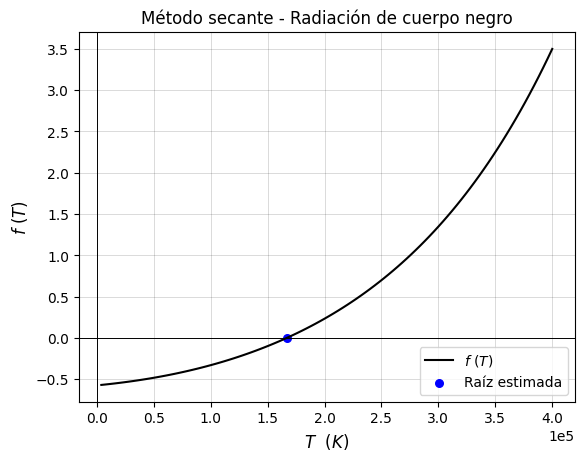

In [47]:
# Método Secante (Derivada hacia atrás)

# Constantes físicas

lambda1, lambda2 = 440, 550 # nm 
R_obs = 0.984
hc_kb = 0.014388 # mK

# Parámetros 

T_starting = [4e3, 8e3]

def f(T):
    num = lambda2**(-5) * (np.exp(hc_kb / lambda1*T) - 1)
    den = lambda1**(-5) * (np.exp(hc_kb / lambda2*T) - 1)
    return num/den - R_obs

# A: Función Secante:

def secante(x_start, f, m):

    counter = 0
    scarborough = 0.5 * 10**(2-m)

    eps = 100

    x_prev, x_current = x_start[0], x_start[1]

    while eps > scarborough:
        x_next = x_current - f(x_current)*(x_current - x_prev)/(f(x_current) - f(x_prev))

        eps = 100 * abs((x_next - x_current)/x_next)
        
        x_prev = x_current
        x_current = x_next 

        counter += 1

    return x_current, counter, eps

T_root, counter, eps = secante(T_starting, f, m=3)

T_cont = np.linspace(4e3, 4e5, 100)
f_cont = f(T_cont)

print(f"Convergencia en {counter} iteraciones: \nT_root = {T_root:.3f} K y f(T_root) = {f(T_root):.6f} con un error relativo de {eps:.3f}%.")

plt.plot(T_cont, f_cont, 'k-', linewidth=1.5, label='$f~(T)$')
plt.scatter(T_root, f(T_root), color='b', s=30, label='Raíz estimada')

plt.axhline(y=0, color='k', linewidth=0.7)
plt.axvline(x=0, color='k', linewidth=0.7)
plt.grid(color='k', linewidth=0.5, alpha=0.2)
plt.xlabel("$T~~(K)$", fontsize=12)
plt.ylabel("$f~(T)$", fontsize=12)
plt.legend(loc='best')
plt.title("Método secante - Radiación de cuerpo negro")
plt.ticklabel_format(style='sci', axis='x', scilimits=(0,0))

plt.show()